/var/folders/m9/_g3wndrn04d80ys2382r700r0000gn/T/ipykernel_81787/1273218504.py:36: FutureWarning: The frame.append method is deprecated and will be removed from pandas in a future version. Use pandas.concat instead.
  subset = subset.append(empty_row, ignore_index=True)
/var/folders/m9/_g3wndrn04d80ys2382r700r0000gn/T/ipykernel_81787/1273218504.py:36: FutureWarning: The frame.append method is deprecated and will be removed from pandas in a future version. Use pandas.concat instead.
  subset = subset.append(empty_row, ignore_index=True)
/var/folders/m9/_g3wndrn04d80ys2382r700r0000gn/T/ipykernel_81787/1273218504.py:36: FutureWarning: The frame.append method is deprecated and will be removed from pandas in a future version. Use pandas.concat instead.
  subset = subset.append(empty_row, ignore_index=True)
/var/folders/m9/_g3wndrn04d80ys2382r700r0000gn/T/ipykernel_81787/1273218504.py:36: FutureWarning: The frame.append method is deprecated and will be removed from pandas in a future version

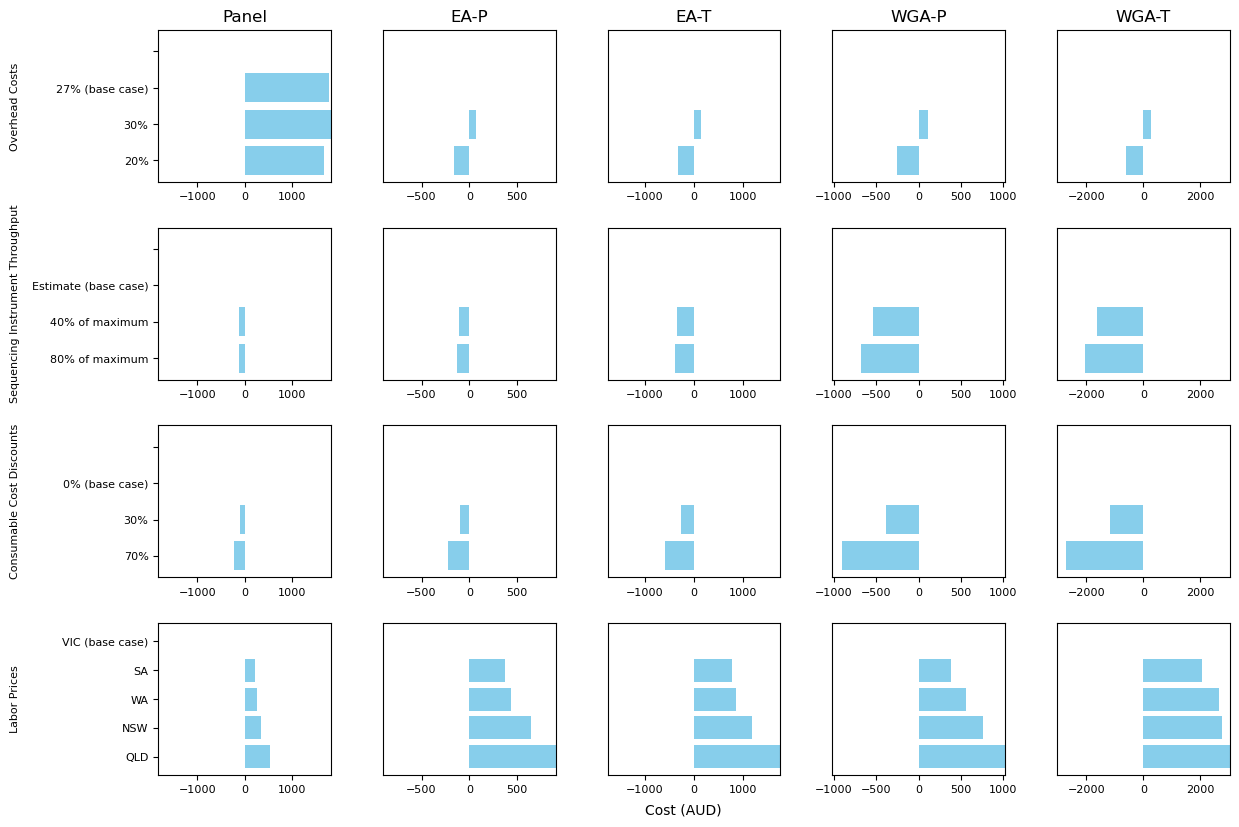

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

# Creating dataframe from the given data
data = {
    "Category": [
        "Overhead Costs",
        "Overhead Costs",
        "Overhead Costs",
        "Sequencing Instrument Throughput",
        "Sequencing Instrument Throughput",
        "Sequencing Instrument Throughput",
        "Consumable Cost Discounts",
        "Consumable Cost Discounts",
        "Consumable Cost Discounts",
        "Labor Prices",
        "Labor Prices",
        "Labor Prices",
        "Labor Prices",
        "Labor Prices",
    ],
    "Scenario": [
        "20%",
        "27% (base case)",
        "30%",
        "Estimate (base case)",
        "40% of maximum",
        "80% of maximum",
        "0% (base case)",
        "30%",
        "70%",
        "VIC (base case)",
        "SA",
        "NSW",
        "QLD",
        "WA",
    ],
    "Panel": [1683, 1781, 1823, 0, -112, -127, 0, -94, -219, 0, 227, 347, 527, 252],
    "EA-P": [-162, 0, 69, 0, -112, -127, 0, -94, -219, 0, 374, 643, 903, 439],
    "EA-T": [-327, 0, 140, 0, -337, -381, 0, -257, -599, 0, 766, 1178, 1758, 862],
    "WGA-P": [-256, 0, 110, 0, -545, -681, 0, -388, -906, 0, 377, 758, 1021, 553],
    "WGA-T": [
        -602,
        0,
        258,
        0,
        -1637,
        -2044,
        0,
        -1165,
        -2718,
        0,
        2070,
        2755,
        3026,
        2635,
    ],
}

df = pd.DataFrame(data)

# Adjusting the layout for A4 landscape
fig, ax = plt.subplots(nrows=len(df["Category"].unique()), ncols=5, figsize=(11.7, 8.3))
fig.tight_layout(pad=2.0)

# Getting the maximum number of scenarios across all categories for uniform bar size
max_scenarios = df.groupby("Category").size().max()

for i, category in enumerate(df["Category"].unique()):
    subset = df[df["Category"] == category].copy()
    subset["abs_sum"] = (
        subset[["Panel", "EA-P", "EA-T", "WGA-P", "WGA-T"]].abs().sum(axis=1)
    )
    subset = subset.sort_values(by="abs_sum", ascending=False).drop(columns="abs_sum")

    # Creating empty scenarios to ensure uniform bar size across subplots
    for _ in range(max_scenarios - len(subset)):
        empty_row = pd.Series(
            {
                "Scenario": "",
                **{group: 0 for group in ["Panel", "EA-P", "EA-T", "WGA-P", "WGA-T"]},
            }
        )
        subset = subset.append(empty_row, ignore_index=True)

    for j, group in enumerate(["Panel", "EA-P", "EA-T", "WGA-P", "WGA-T"]):
        ax[i, j].barh(subset["Scenario"], subset[group], color="skyblue")

        if i == 0:
            ax[i, j].set_title(group)

        ax[i, j].set_xlim(
            -max(abs(df[group].min()), df[group].max()),
            max(abs(df[group].min()), df[group].max()),
        )

        if j != 0:
            ax[i, j].yaxis.set_visible(False)

        # Moving the category labels further to the left
        if j == 0:
            ax[i, j].yaxis.tick_left()
            ax[i, j].yaxis.set_label_coords(-0.8, 0.5)
            ax[i, j].set_ylabel(category, fontsize=8)

        ax[i, j].tick_params(axis="both", which="major", labelsize=8)
        ax[i, j].tick_params(axis="both", which="minor", labelsize=6)

# Adding a centralized x-axis label with adjusted position
fig.text(0.5, 0.02, "Cost (AUD)", ha="center", va="center", fontsize=10)

plt.subplots_adjust(wspace=0.3, hspace=0.3)
plt.savefig(
    "tornado_diagram_A4_landscape_uniform_bars_corrected.png",
    dpi=300,
    format="png",
    bbox_inches="tight",
)
plt.show()

/var/folders/m9/_g3wndrn04d80ys2382r700r0000gn/T/ipykernel_81787/566360020.py:34: FutureWarning: The frame.append method is deprecated and will be removed from pandas in a future version. Use pandas.concat instead.
  subset = subset.append(empty_row, ignore_index=True)
/var/folders/m9/_g3wndrn04d80ys2382r700r0000gn/T/ipykernel_81787/566360020.py:34: FutureWarning: The frame.append method is deprecated and will be removed from pandas in a future version. Use pandas.concat instead.
  subset = subset.append(empty_row, ignore_index=True)
/var/folders/m9/_g3wndrn04d80ys2382r700r0000gn/T/ipykernel_81787/566360020.py:34: FutureWarning: The frame.append method is deprecated and will be removed from pandas in a future version. Use pandas.concat instead.
  subset = subset.append(empty_row, ignore_index=True)
/var/folders/m9/_g3wndrn04d80ys2382r700r0000gn/T/ipykernel_81787/566360020.py:34: FutureWarning: The frame.append method is deprecated and will be removed from pandas in a future version. Us

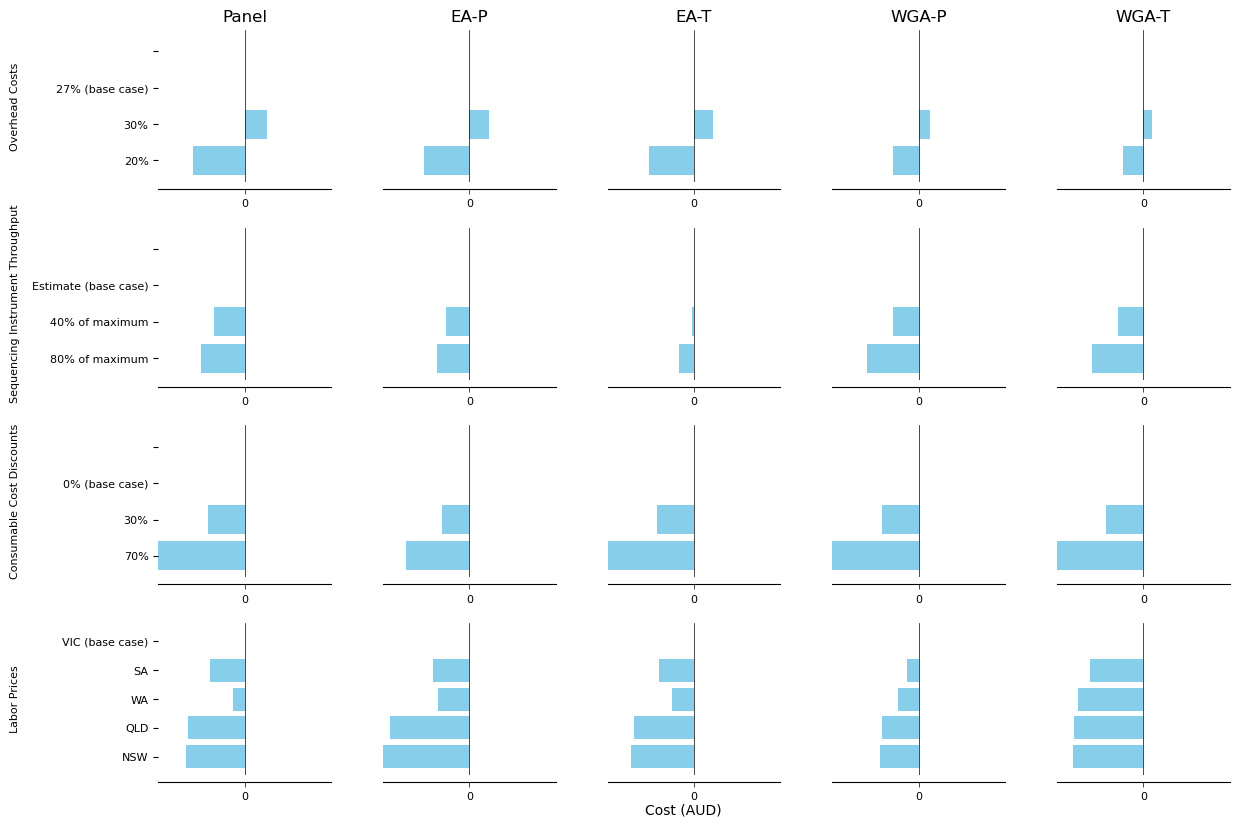

In [2]:
import pandas as pd
import matplotlib.pyplot as plt

# Creating dataframe from the given data
data = {
    "Category": [
        "Overhead Costs",
        "Overhead Costs",
        "Overhead Costs",
        "Sequencing Instrument Throughput",
        "Sequencing Instrument Throughput",
        "Sequencing Instrument Throughput",
        "Consumable Cost Discounts",
        "Consumable Cost Discounts",
        "Consumable Cost Discounts",
        "Labor Prices",
        "Labor Prices",
        "Labor Prices",
        "Labor Prices",
        "Labor Prices",
    ],
    "Scenario": [
        "20%",
        "27% (base case)",
        "30%",
        "Estimate (base case)",
        "40% of maximum",
        "80% of maximum",
        "0% (base case)",
        "30%",
        "70%",
        "VIC (base case)",
        "SA",
        "NSW",
        "QLD",
        "WA",
    ],
    "Panel": [-131, 0, 56, 0, -79, -110, 0, -94, -219, 0, -88, -148, -143, -29],
    "EA-P": [-156, 0, 67, 0, -79, -110, 0, -94, -219, 0, -124, -297, -273, -107],
    "EA-T": [-313, 0, 134, 0, -11, -105, 0, -257, -599, 0, -244, -438, -417, -153],
    "WGA-P": [-267, 0, 114, 0, -266, -541, 0, -388, -906, 0, -125, -408, -384, -217],
    "WGA-T": [
        -639,
        0,
        274,
        0,
        -799,
        -1625,
        0,
        -1165,
        -2718,
        0,
        -1665,
        -2210,
        -2179,
        -2052,
    ],
}

df = pd.DataFrame(data)

# Adjusting the layout for A4 landscape
fig, ax = plt.subplots(nrows=len(df["Category"].unique()), ncols=5, figsize=(11.7, 8.3))
fig.tight_layout(pad=2.0)
max_scenarios = df.groupby("Category").size().max()

for i, category in enumerate(df["Category"].unique()):
    subset = df[df["Category"] == category].copy()
    subset["abs_sum"] = (
        subset[["Panel", "EA-P", "EA-T", "WGA-P", "WGA-T"]].abs().sum(axis=1)
    )
    subset = subset.sort_values(by="abs_sum", ascending=False).drop(columns="abs_sum")

    # Creating empty scenarios to ensure uniform bar size across subplots
    for _ in range(max_scenarios - len(subset)):
        empty_row = pd.Series(
            {
                "Scenario": "",
                **{group: 0 for group in ["Panel", "EA-P", "EA-T", "WGA-P", "WGA-T"]},
            }
        )
        subset = subset.append(empty_row, ignore_index=True)

    for j, group in enumerate(["Panel", "EA-P", "EA-T", "WGA-P", "WGA-T"]):
        ax[i, j].barh(subset["Scenario"], subset[group], color="skyblue")
        if i == 0:
            ax[i, j].set_title(group)
        ax[i, j].set_xlim(
            -max(abs(df[group].min()), df[group].max()),
            max(abs(df[group].min()), df[group].max()),
        )
        if j != 0:
            ax[i, j].yaxis.set_visible(False)
        if j == 0:
            ax[i, j].yaxis.tick_left()
            ax[i, j].yaxis.set_label_coords(-0.8, 0.5)
            ax[i, j].set_ylabel(category, fontsize=8)
            ax[i, j].yaxis.grid(False)
        ax[i, j].tick_params(axis="both", which="major", labelsize=8)
        ax[i, j].tick_params(axis="both", which="minor", labelsize=6)
        for spine in ax[i, j].spines.values():
            spine.set_visible(False)
        ax[i, j].spines["bottom"].set_position(("outward", 5))
        ax[i, j].spines["bottom"].set_visible(True)
        ax[i, j].xaxis.set_ticks_position("bottom")
        ax[i, j].xaxis.set_tick_params(width=0.5)
        ax[i, j].set_xticks([0])
        ax[i, j].xaxis.grid(False)
        ax[i, j].axvline(x=0, color="black", linewidth=0.5)

fig.text(0.5, 0.02, "Cost (AUD)", ha="center", va="center", fontsize=10)
plt.subplots_adjust(wspace=0.3, hspace=0.3)
plt.show()

/var/folders/m9/_g3wndrn04d80ys2382r700r0000gn/T/ipykernel_81787/396099926.py:48: UserWarning: FixedFormatter should only be used together with FixedLocator
  axs[i, j].set_xticklabels(new_labels)


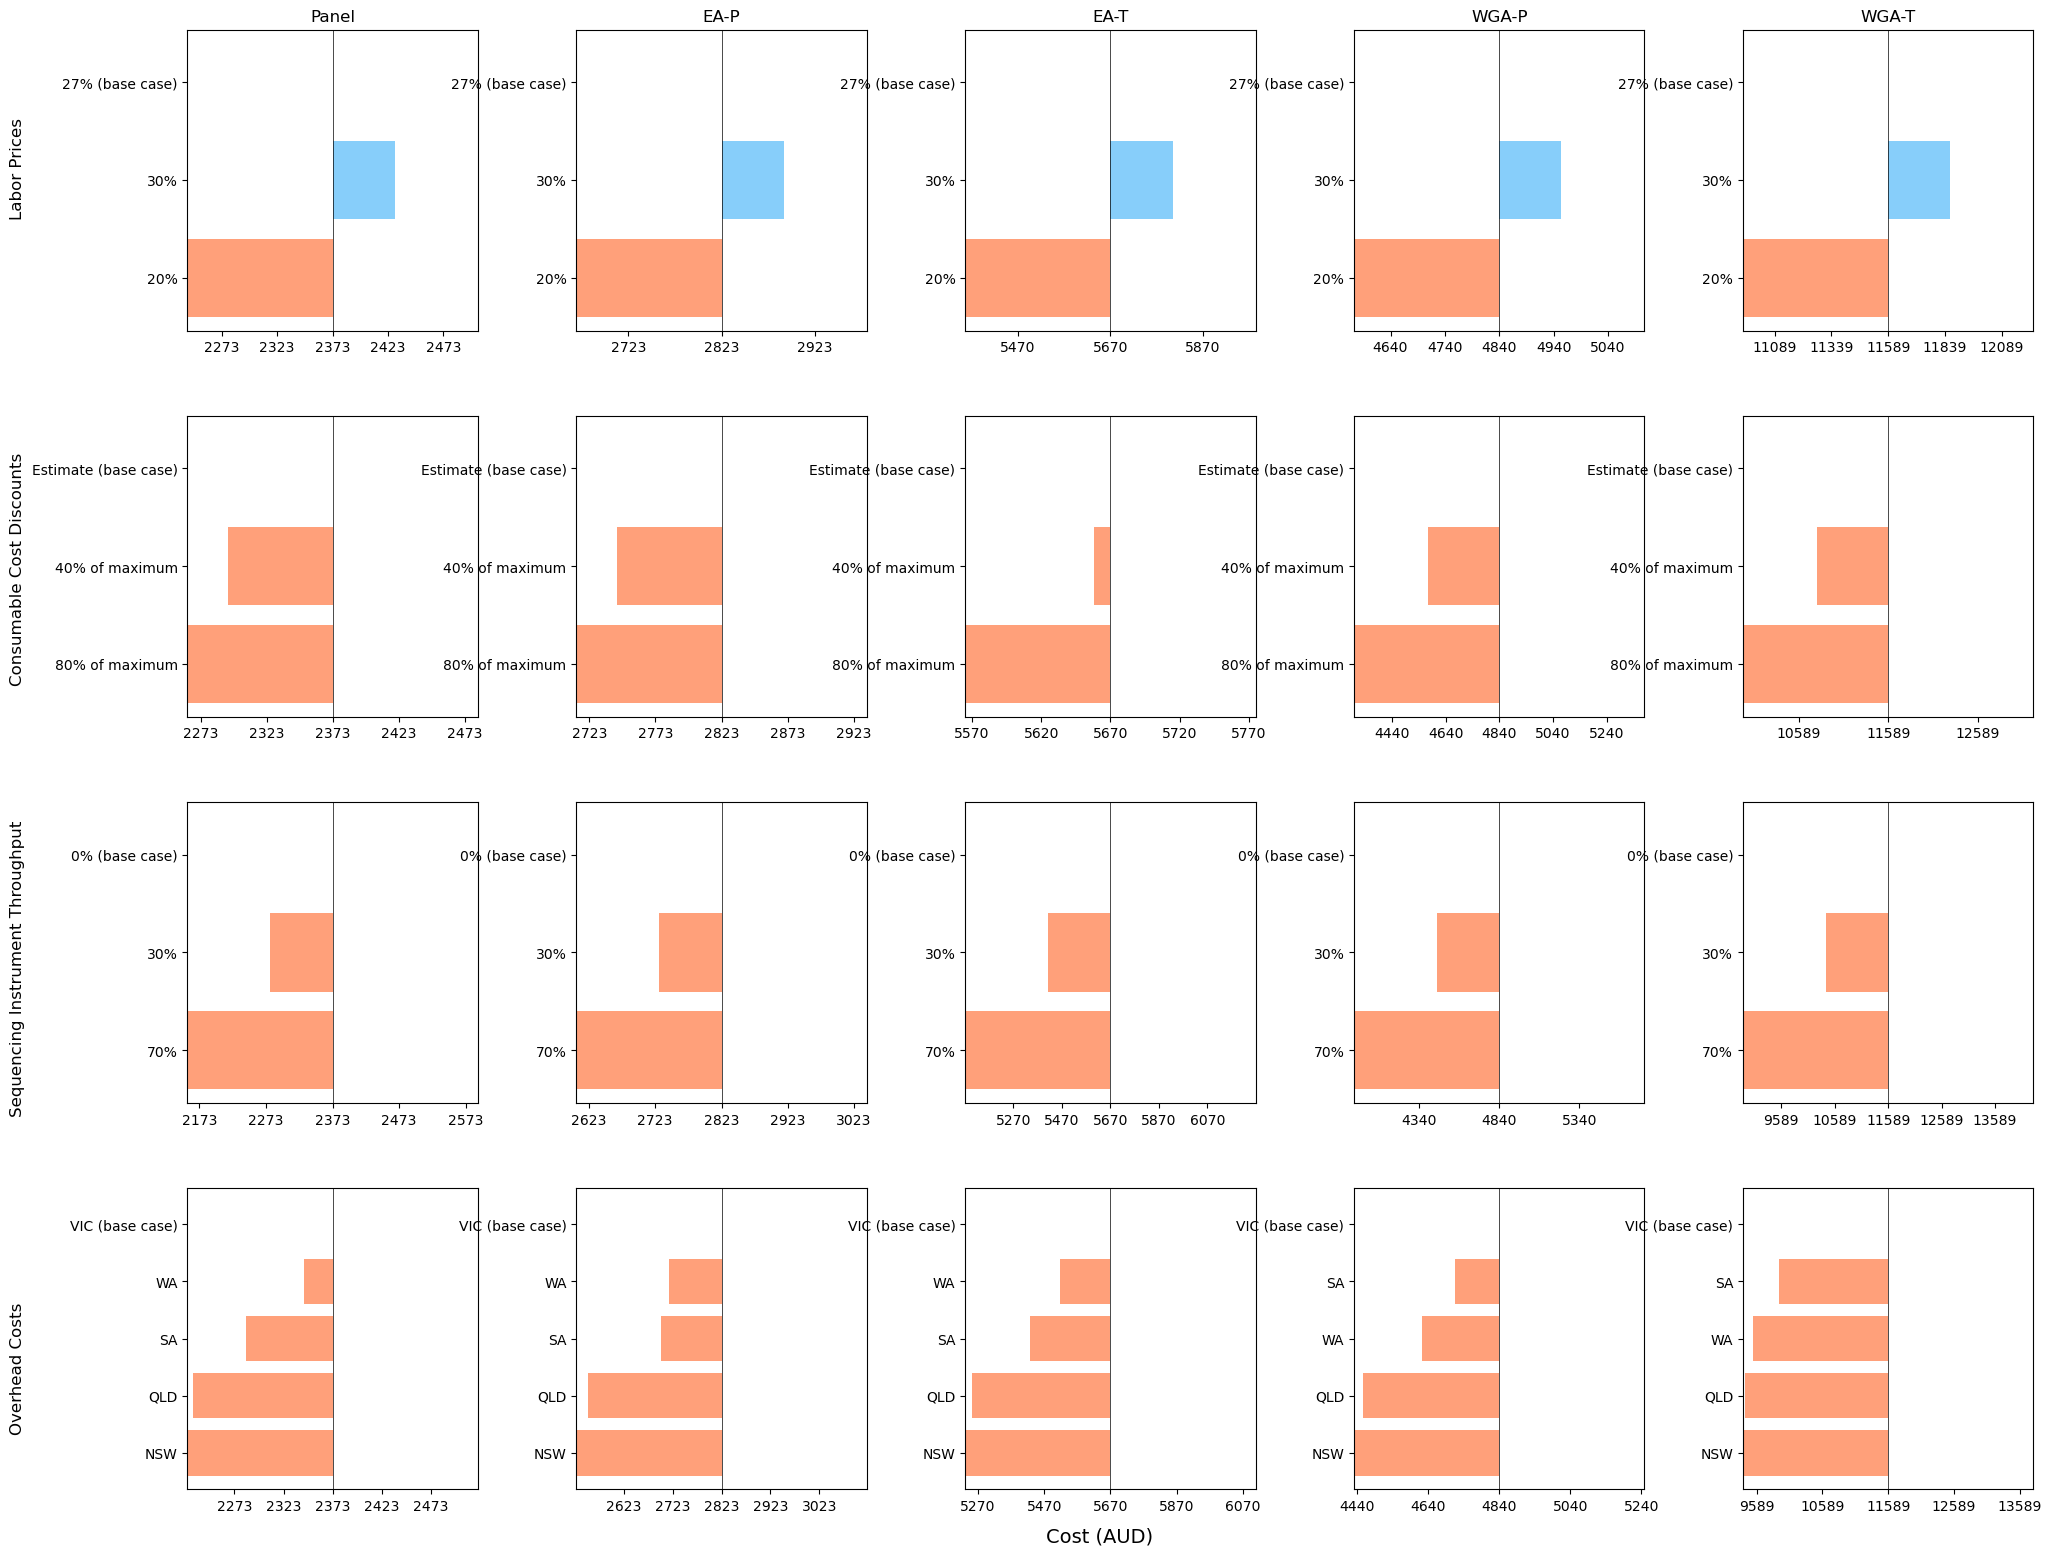

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Load the data
data = pd.read_csv(
    "/Users/doughnut/Library/CloudStorage/OneDrive-TheUniversityofMelbourne/Phase 1 - Study 1 - Microcosting - Model 1/MicrocostingDSA20230817(Actual).csv"
)

# Colors for the bars
positive_color = "#87CEFA"  # Sky blue
negative_color = "#FFA07A"  # Light salmon

# Identify the unique values for "Test" and "Category"
unique_tests = data["Test"].unique()
unique_categories = data["Category"].unique()

# Create the visualization
fig, axs = plt.subplots(4, 5, figsize=(20, 16))
fig.tight_layout(pad=4.0)

for i, category in enumerate(unique_categories):
    for j, test in enumerate(unique_tests):
        # Filter the data for the current combination
        subset = data[(data["Test"] == test) & (data["Category"] == category)]

        # Find the base case value
        base_case_value = subset[subset["Scenario"].str.contains("base case")][
            "Value"
        ].values[0]

        # Calculate the difference for each scenario from the base case value
        differences = subset["Value"] - base_case_value

        # Sort scenarios based on the absolute difference from the base case in descending order
        sorted_indices = np.argsort(np.abs(differences))[::-1]
        sorted_differences = differences.iloc[sorted_indices].values
        sorted_scenarios = subset["Scenario"].iloc[sorted_indices].values

        # Determine the range for the x-axis
        range_max = max(abs(sorted_differences))

        # Plot the tornado diagram
        axs[i, j].barh(
            sorted_scenarios,
            sorted_differences,
            color=np.where(sorted_differences >= 0, positive_color, negative_color),
        )
        axs[i, j].axvline(x=0, color="black", linewidth=0.5)  # Reference line
        axs[i, j].set_xlim(-range_max, range_max)

        # Adjusting x-ticks to display base case value instead of 0
        current_ticks = axs[i, j].get_xticks()
        new_labels = [str(int(tick + base_case_value)) for tick in current_ticks]
        axs[i, j].set_xticklabels(new_labels)

        # Remove title for all but the top row
        if i == 0:
            axs[i, j].set_title(f"{test}")
        else:
            axs[i, j].set_title("")

        # Remove y labels for all but the leftmost column
        if j != 0:
            axs[i, j].set_ylabel("")

# Adjusting the position of the vertical "Category" labels to -0.06
for i, category in enumerate(unique_categories):
    fig.text(
        -0.045,
        (i + 0.5) / 4,
        category,
        fontsize=12,
        rotation=90,
        verticalalignment="center",
    )

# Positioning x-axis label to 0.02 above the bottom
fig.text(0.5, 0.02, "Cost (AUD)", ha="center", va="center", fontsize=14)

plt.show()

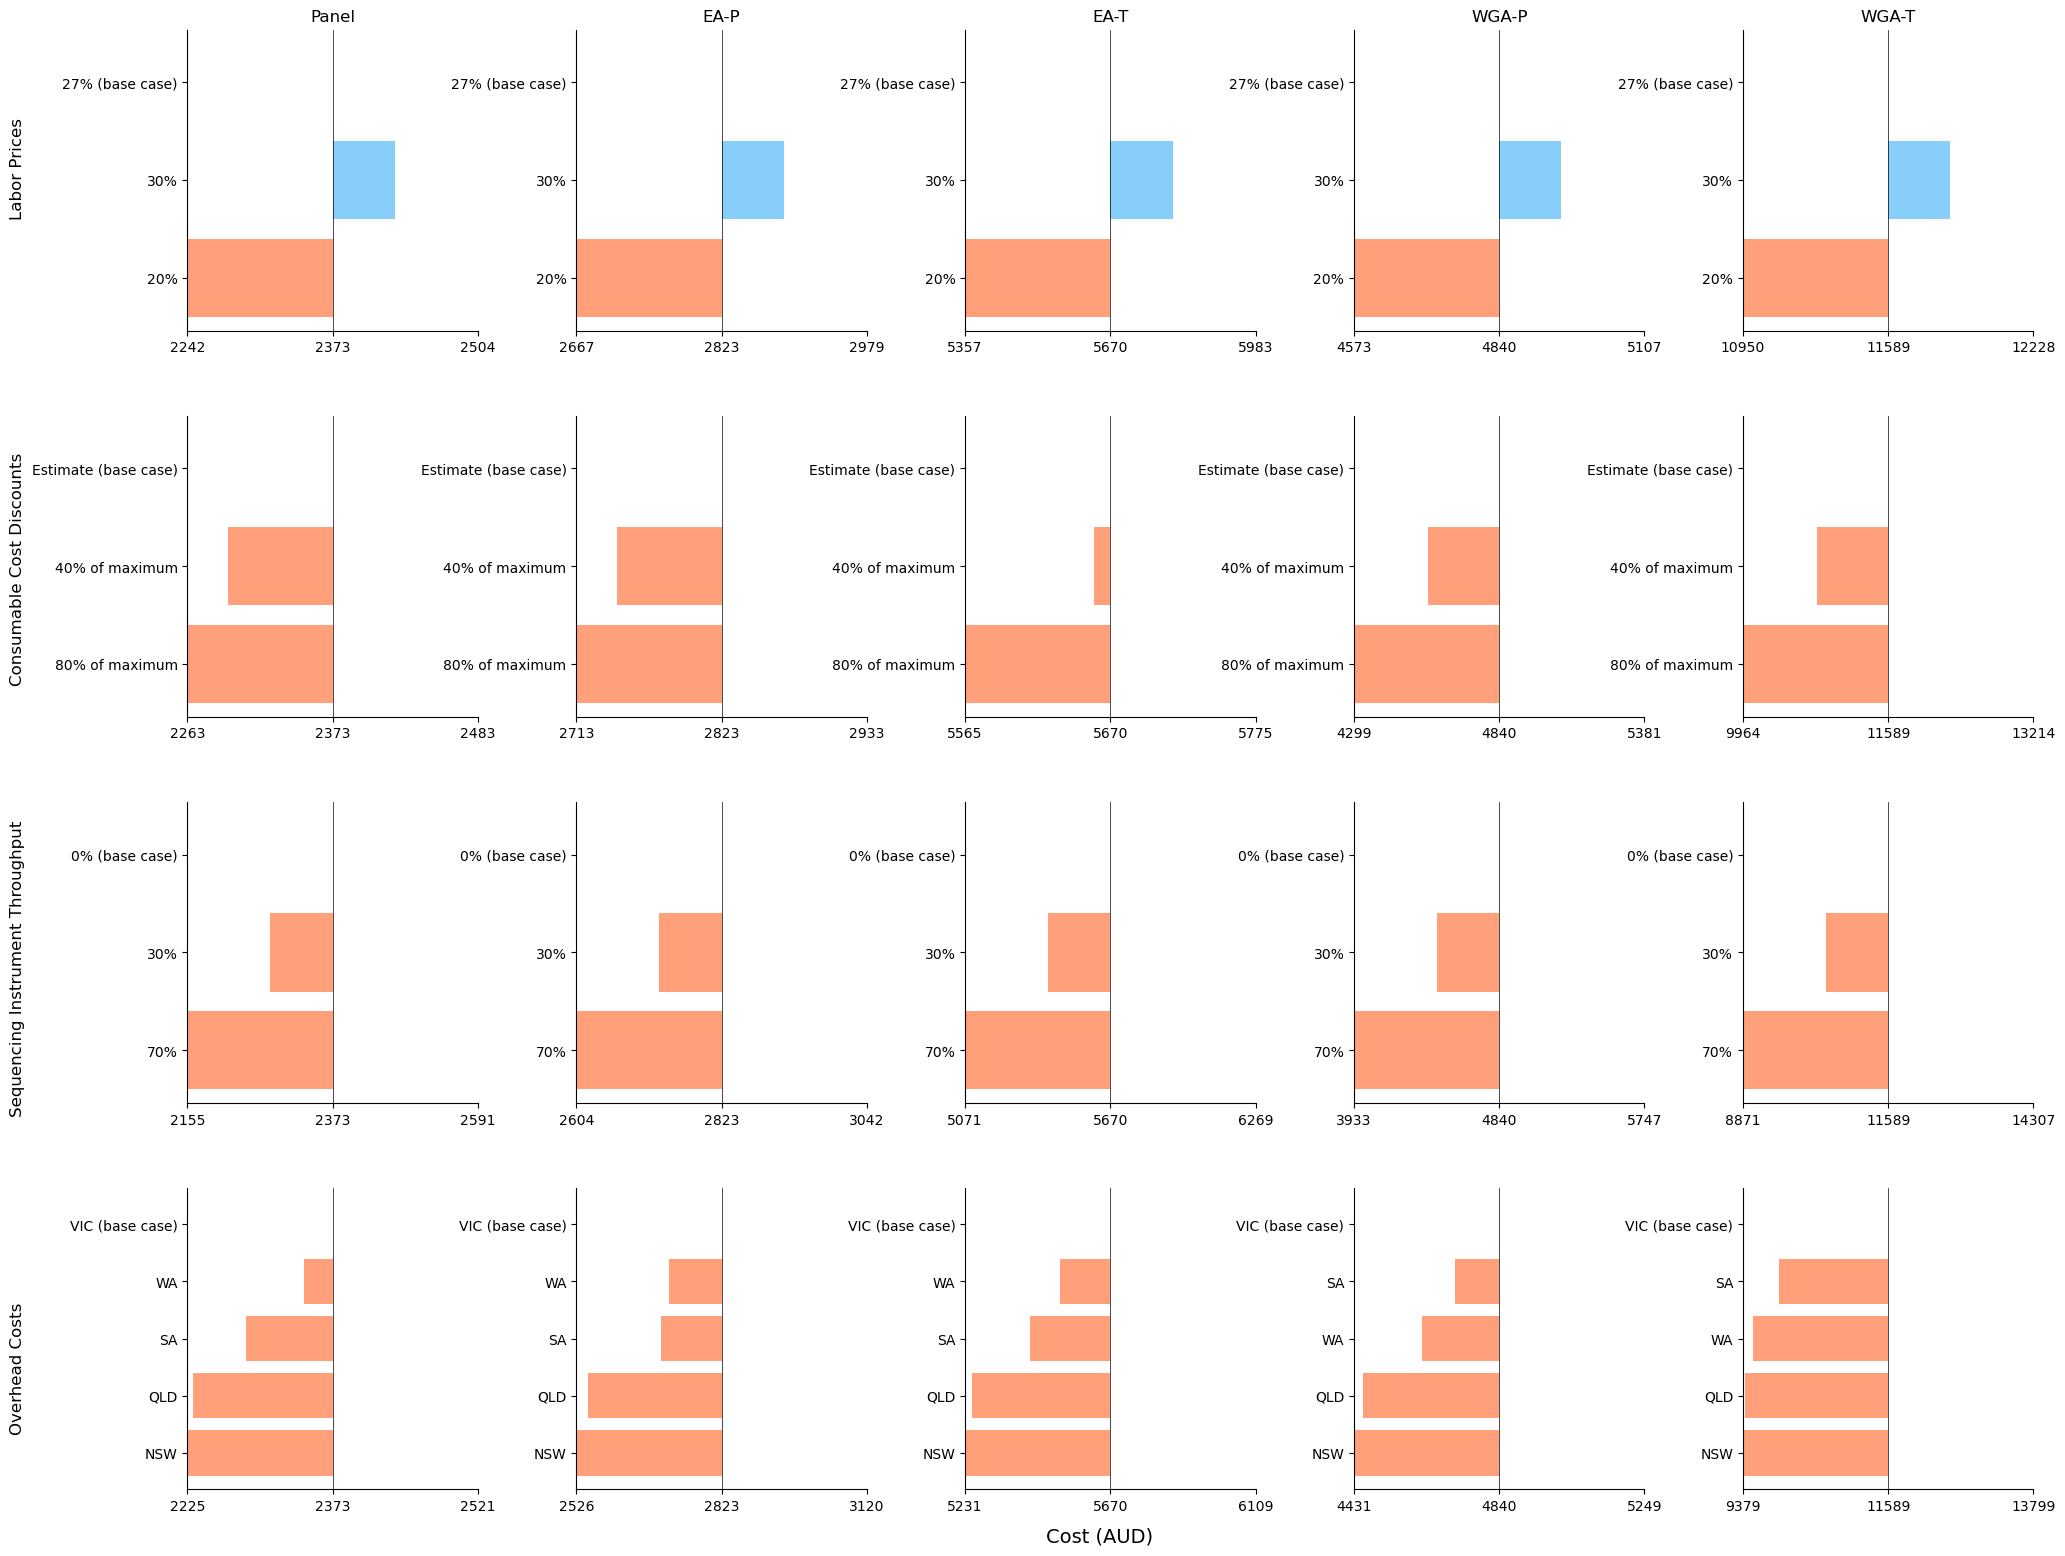

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Read the CSV file
data = pd.read_csv(
    "/Users/doughnut/Library/CloudStorage/OneDrive-TheUniversityofMelbourne/Phase 1 - Study 1 - Microcosting - Model 1/MicrocostingDSA20230817(Actual).csv",
    usecols=["Test", "Category", "Scenario", "Value"],
)

# Unique tests and categories
unique_tests = data["Test"].unique()
unique_categories = data["Category"].unique()

# Colors for the bars
positive_color = "#87CEFA"  # Sky blue
negative_color = "#FFA07A"  # Light salmon

# Setting up the figure and subplots
fig, axs = plt.subplots(4, 5, figsize=(20, 16))
fig.tight_layout(pad=4.0)

for i, category in enumerate(unique_categories):
    for j, test in enumerate(unique_tests):
        # Filter data for the current combination
        subset = data[(data["Test"] == test) & (data["Category"] == category)]

        # Find the base case value
        base_case_value = subset[subset["Scenario"].str.contains("base case")][
            "Value"
        ].values[0]

        # Calculate difference from base case value for each scenario
        differences = subset["Value"] - base_case_value

        # Sort scenarios based on the absolute difference from the base case
        sorted_indices = np.argsort(np.abs(differences))[::-1]
        sorted_differences = differences.iloc[sorted_indices].values
        sorted_scenarios = subset["Scenario"].iloc[sorted_indices].values

        # Determine x-axis range
        range_max = max(abs(sorted_differences))

        # Plotting the tornado diagram
        axs[i, j].barh(
            sorted_scenarios,
            sorted_differences,
            color=np.where(sorted_differences >= 0, positive_color, negative_color),
        )
        axs[i, j].axvline(x=0, color="black", linewidth=0.5)  # Reference line
        axs[i, j].set_xlim(-range_max, range_max)

        # Adjust x-ticks to display only three values
        axs[i, j].set_xticks([-range_max, 0, range_max])
        axs[i, j].set_xticklabels(
            [
                int(base_case_value - range_max),
                int(base_case_value),
                int(base_case_value + range_max),
            ]
        )

        # Adjust titles and y labels
        if i == 0:
            axs[i, j].set_title(f"{test}")
        else:
            axs[i, j].set_title("")
        if j != 0:
            axs[i, j].set_ylabel("")

        # Removing the top and right spines
        axs[i, j].spines["top"].set_visible(False)
        axs[i, j].spines["right"].set_visible(False)

# Positioning the vertical "Category" labels
for i, category in enumerate(unique_categories):
    fig.text(
        -0.045,
        (i + 0.5) / 4,
        category,
        fontsize=12,
        rotation=90,
        verticalalignment="center",
    )

# Positioning the x-axis label
fig.text(0.5, 0.02, "Cost (AUD)", ha="center", va="center", fontsize=14)

plt.show()

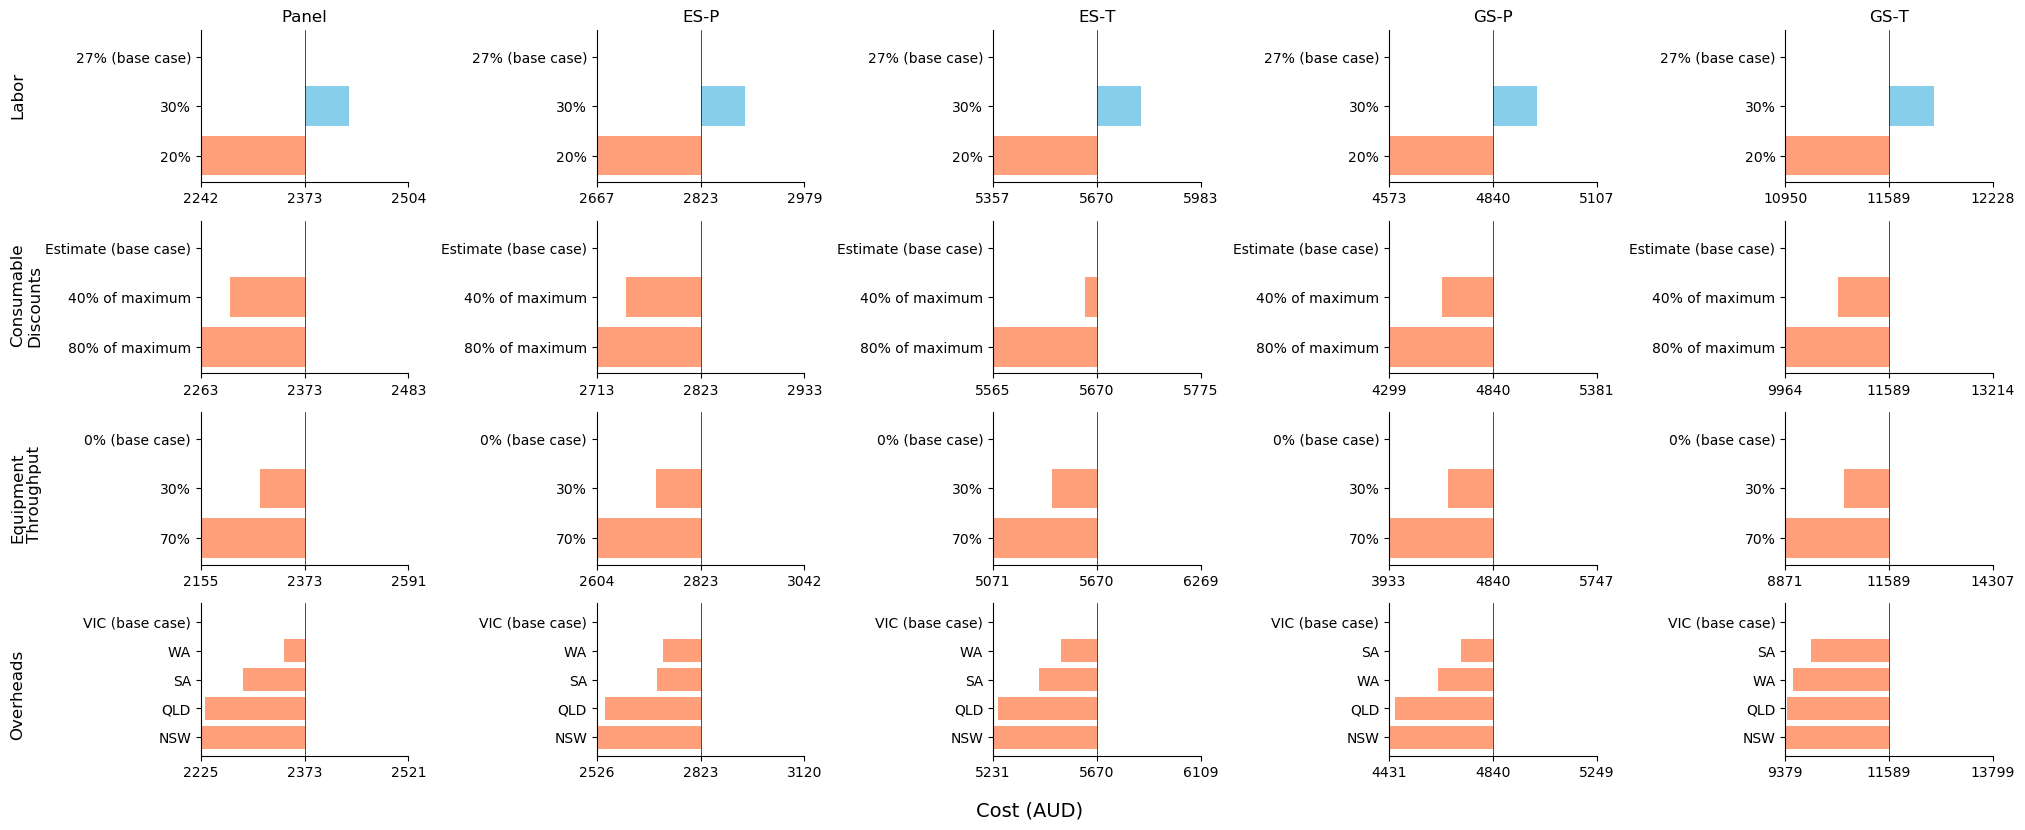

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Load the data
data = pd.read_csv(
    "/Users/doughnut/Library/CloudStorage/OneDrive-TheUniversityofMelbourne/Phase 1 - Study 1 - Microcosting - Model 1/MicrocostingDSA20230817(Actual).csv",
    usecols=["Test", "Category", "Scenario", "Value"],
)

# Define unique tests and categories for subplots
unique_tests = data["Test"].unique()
unique_categories = data["Category"].unique()

# Define colors for positive and negative differences
positive_color = "#87CEEB"  # Sky blue
negative_color = "#FFA07A"  # Light salmon


# Define a function to plot individual tornado diagrams
def plot_tornado(subset, ax):
    base_case_value = subset[subset["Scenario"].str.contains("base case")][
        "Value"
    ].values[0]
    differences = subset["Value"] - base_case_value
    sorted_indices = np.argsort(np.abs(differences))[::-1]
    sorted_differences = differences.iloc[sorted_indices].values
    sorted_scenarios = subset["Scenario"].iloc[sorted_indices].values
    range_max = max(abs(sorted_differences))
    ax.barh(
        sorted_scenarios,
        sorted_differences,
        color=np.where(sorted_differences >= 0, positive_color, negative_color),
    )
    ax.axvline(x=0, color="black", linewidth=0.5)
    ax.set_xlim(-range_max, range_max)
    ax.set_xticks([-range_max, 0, range_max])
    ax.set_xticklabels(
        [
            int(base_case_value - range_max),
            int(base_case_value),
            int(base_case_value + range_max),
        ]
    )
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["bottom"].set_visible(True)
    ax.spines["left"].set_visible(True)


# Generate the tornado diagrams with further reduced height
fig, axs = plt.subplots(4, 5, figsize=(20, 8), tight_layout=True)

for i, category in enumerate(unique_categories):
    for j, test in enumerate(unique_tests):
        subset = data[(data["Test"] == test) & (data["Category"] == category)]
        plot_tornado(subset, axs[i, j])
        if i == 0:
            axs[i, j].set_title(f"{test}")
        if j != 0:
            axs[i, j].set_ylabel("")

# Adjusting the position of the vertical "Category" labels with modified categories
modified_categories = [
    "Overheads",
    "Equipment\nThroughput",
    "Consumable\nDiscounts",
    "Labor",
]

for i, category in enumerate(modified_categories):
    fig.text(
        -0.01,
        (i + 0.5) / 4,
        category,
        fontsize=12,
        rotation=90,
        verticalalignment="center",
    )

# Positioning x-axis label
fig.text(0.5, -0.02, "Cost (AUD)", ha="center", va="center", fontsize=14)

plt.show()

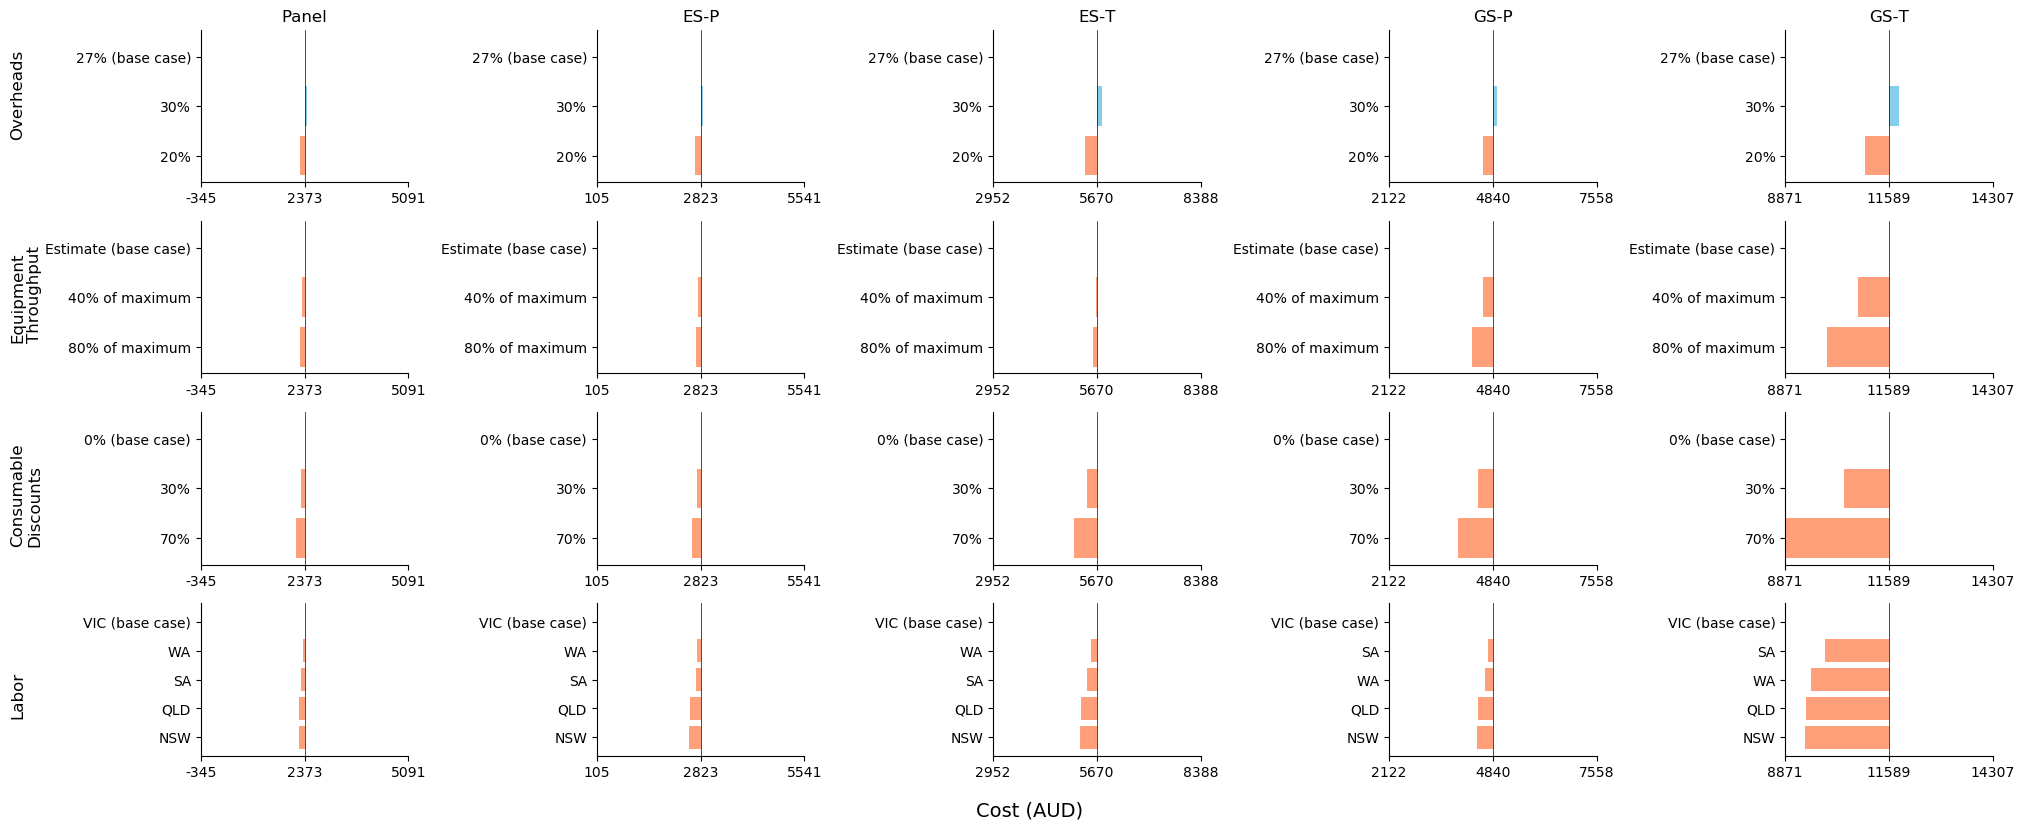

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Load the data
data = pd.read_csv(
    "/Users/doughnut/Library/CloudStorage/OneDrive-TheUniversityofMelbourne/Phase 1 - Study 1 - Microcosting - Model 1/MicrocostingDSA20230817(Actual).csv",
    usecols=["Test", "Category", "Scenario", "Value"],
)

# Define unique tests and categories for subplots
unique_tests = data["Test"].unique()
unique_categories = data["Category"].unique()

# Define colors for positive and negative differences
positive_color = "#87CEEB"  # Sky blue
negative_color = "#FFA07A"  # Light salmon

# Compute the global maximum absolute difference
global_max_diff = 0
for category in unique_categories:
    for test in unique_tests:
        subset = data[(data["Test"] == test) & (data["Category"] == category)]
        base_case_value = subset[subset["Scenario"].str.contains("base case")][
            "Value"
        ].values[0]
        differences = subset["Value"] - base_case_value
        max_diff = max(abs(differences))
        global_max_diff = max(global_max_diff, max_diff)


# Define a function to plot individual tornado diagrams
def plot_tornado(subset, ax):
    base_case_value = subset[subset["Scenario"].str.contains("base case")][
        "Value"
    ].values[0]
    differences = subset["Value"] - base_case_value
    sorted_indices = np.argsort(np.abs(differences))[::-1]
    sorted_differences = differences.iloc[sorted_indices].values
    sorted_scenarios = subset["Scenario"].iloc[sorted_indices].values
    ax.barh(
        sorted_scenarios,
        sorted_differences,
        color=np.where(sorted_differences >= 0, positive_color, negative_color),
    )
    ax.axvline(x=0, color="black", linewidth=0.5)
    ax.set_xlim(-global_max_diff, global_max_diff)
    ax.set_xticks([-global_max_diff, 0, global_max_diff])
    ax.set_xticklabels(
        [
            int(base_case_value - global_max_diff),
            int(base_case_value),
            int(base_case_value + global_max_diff),
        ]
    )
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["bottom"].set_visible(True)
    ax.spines["left"].set_visible(True)


# Generate the tornado diagrams with further reduced height
fig, axs = plt.subplots(4, 5, figsize=(20, 8), tight_layout=True)

for i, category in enumerate(unique_categories):
    for j, test in enumerate(unique_tests):
        subset = data[(data["Test"] == test) & (data["Category"] == category)]
        plot_tornado(subset, axs[i, j])
        if i == 0:
            axs[i, j].set_title(f"{test}")
        if j != 0:
            axs[i, j].set_ylabel("")

# Adjusting the position of the vertical "Category" labels with modified categories
# modified_categories = [
#    "Overheads",
#    "Equipment\nThroughput",
#    "Consumable\nDiscounts",
#    "Labor"
# ]
modified_categories = [
    "Labor",
    "Consumable\nDiscounts",
    "Equipment\nThroughput",
    "Overheads",
]

for i, category in enumerate(modified_categories):
    fig.text(
        -0.01,
        (i + 0.5) / 4,
        category,
        fontsize=12,
        rotation=90,
        verticalalignment="center",
    )

# Positioning x-axis label
fig.text(0.5, -0.02, "Cost (AUD)", ha="center", va="center", fontsize=14)

plt.show()

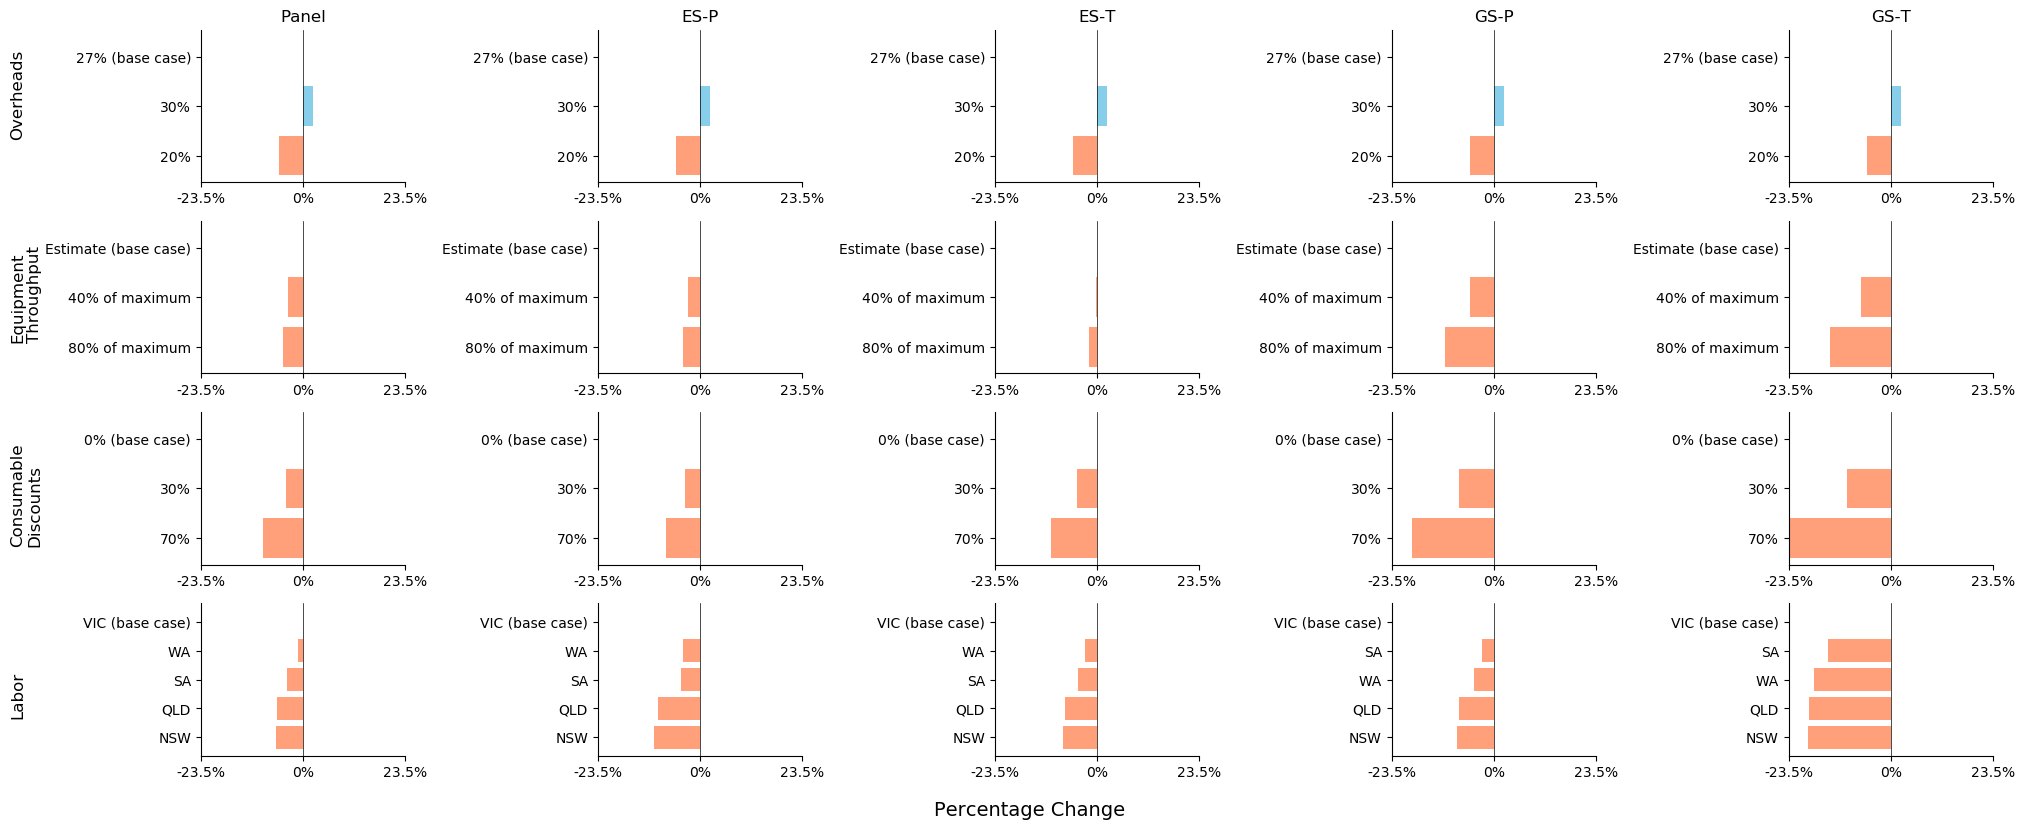

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Load the data
data = pd.read_csv(
    "/Users/doughnut/Library/CloudStorage/OneDrive-TheUniversityofMelbourne/Phase 1 - Study 1 - Microcosting - Model 1/MicrocostingDSA20230817(Actual).csv",
    usecols=["Test", "Category", "Scenario", "Value"],
)

# Define unique tests and categories for subplots
unique_tests = data["Test"].unique()
unique_categories = data["Category"].unique()

# Define colors for positive and negative differences
positive_color = "#87CEEB"  # Sky blue
negative_color = "#FFA07A"  # Light salmon

# Compute the global maximum percentage difference
global_max_percentage_diff = 0
for category in unique_categories:
    for test in unique_tests:
        subset = data[(data["Test"] == test) & (data["Category"] == category)]
        base_case_value = subset[subset["Scenario"].str.contains("base case")][
            "Value"
        ].values[0]
        percentage_differences = (
            (subset["Value"] - base_case_value) / base_case_value
        ) * 100
        max_percentage_diff = max(abs(percentage_differences))
        global_max_percentage_diff = max(
            global_max_percentage_diff, max_percentage_diff
        )


# Define a function to plot individual tornado diagrams
def plot_tornado(subset, ax):
    base_case_value = subset[subset["Scenario"].str.contains("base case")][
        "Value"
    ].values[0]
    percentage_differences = (
        (subset["Value"] - base_case_value) / base_case_value
    ) * 100
    sorted_indices = np.argsort(np.abs(percentage_differences))[::-1]
    sorted_percentage_differences = percentage_differences.iloc[sorted_indices].values
    sorted_scenarios = subset["Scenario"].iloc[sorted_indices].values
    ax.barh(
        sorted_scenarios,
        sorted_percentage_differences,
        color=np.where(
            sorted_percentage_differences >= 0, positive_color, negative_color
        ),
    )
    ax.axvline(x=0, color="black", linewidth=0.5)
    ax.set_xlim(-global_max_percentage_diff, global_max_percentage_diff)
    ax.set_xticks([-global_max_percentage_diff, 0, global_max_percentage_diff])
    ax.set_xticklabels(
        [
            f"{-global_max_percentage_diff:.1f}%",
            "0%",
            f"{global_max_percentage_diff:.1f}%",
        ]
    )
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["bottom"].set_visible(True)
    ax.spines["left"].set_visible(True)


# Generate the tornado diagrams
fig, axs = plt.subplots(
    len(unique_categories), len(unique_tests), figsize=(20, 8), tight_layout=True
)

for i, category in enumerate(unique_categories):
    for j, test in enumerate(unique_tests):
        subset = data[(data["Test"] == test) & (data["Category"] == category)]
        plot_tornado(subset, axs[i, j])
        if i == 0:
            axs[i, j].set_title(f"{test}")
        if j != 0:
            axs[i, j].set_ylabel("")

# Adjusting the position of the vertical "Category" labels
modified_categories = [
    "Labor",
    "Consumable\nDiscounts",
    "Equipment\nThroughput",
    "Overheads",
]

for i, category in enumerate(modified_categories):
    fig.text(
        -0.01,
        (i + 0.5) / len(unique_categories),
        category,
        fontsize=12,
        rotation=90,
        verticalalignment="center",
    )

# Positioning x-axis label
fig.text(0.5, -0.02, "Percentage Change", ha="center", va="center", fontsize=14)

plt.show()

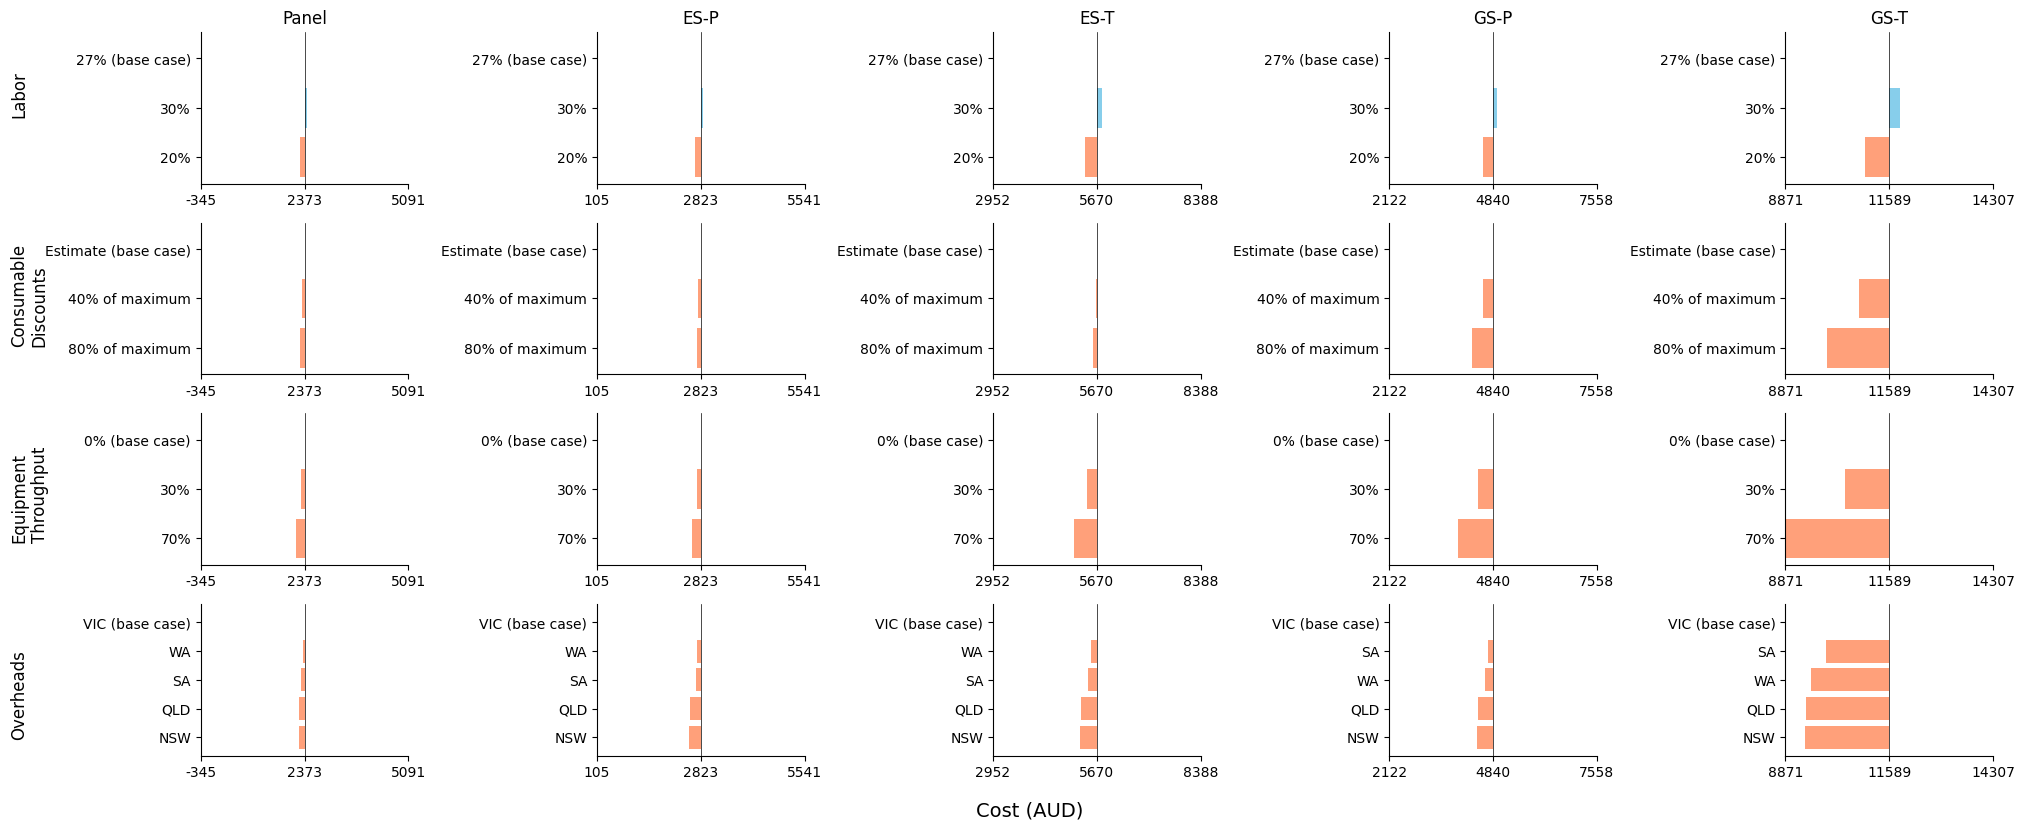

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.backends.backend_pdf import PdfPages  # Import PDFPages

# Load the data
data = pd.read_csv(
    "/Users/doughnut/Library/CloudStorage/OneDrive-TheUniversityofMelbourne/Phase 1 - Study 1 - Microcosting - Model 1/MicrocostingDSA20230817(Actual).csv",
    usecols=["Test", "Category", "Scenario", "Value"],
)

# Define unique tests and categories for subplots
unique_tests = data["Test"].unique()
unique_categories = data["Category"].unique()

# Define colors for positive and negative differences
positive_color = "#87CEEB"  # Sky blue
negative_color = "#FFA07A"  # Light salmon

# Compute the global maximum absolute difference
global_max_diff = 0
for category in unique_categories:
    for test in unique_tests:
        subset = data[(data["Test"] == test) & (data["Category"] == category)]
        base_case_value = subset[subset["Scenario"].str.contains("base case")][
            "Value"
        ].values[0]
        differences = subset["Value"] - base_case_value
        max_diff = max(abs(differences))
        global_max_diff = max(global_max_diff, max_diff)


# Define a function to plot individual tornado diagrams
def plot_tornado(subset, ax):
    base_case_value = subset[subset["Scenario"].str.contains("base case")][
        "Value"
    ].values[0]
    differences = subset["Value"] - base_case_value
    sorted_indices = np.argsort(np.abs(differences))[::-1]
    sorted_differences = differences.iloc[sorted_indices].values
    sorted_scenarios = subset["Scenario"].iloc[sorted_indices].values
    ax.barh(
        sorted_scenarios,
        sorted_differences,
        color=np.where(sorted_differences >= 0, positive_color, negative_color),
    )
    ax.axvline(x=0, color="black", linewidth=0.5)
    ax.set_xlim(-global_max_diff, global_max_diff)
    ax.set_xticks([-global_max_diff, 0, global_max_diff])
    ax.set_xticklabels(
        [
            int(base_case_value - global_max_diff),
            int(base_case_value),
            int(base_case_value + global_max_diff),
        ]
    )
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["bottom"].set_visible(True)
    ax.spines["left"].set_visible(True)


# Generate the tornado diagrams with further reduced height
fig, axs = plt.subplots(4, 5, figsize=(20, 8), tight_layout=True)

for i, category in enumerate(unique_categories):
    for j, test in enumerate(unique_tests):
        subset = data[(data["Test"] == test) & (data["Category"] == category)]
        plot_tornado(subset, axs[i, j])
        if i == 0:
            axs[i, j].set_title(f"{test}")
        if j != 0:
            axs[i, j].set_ylabel("")

# Adjusting the position of the vertical "Category" labels with modified categories
modified_categories = [
    "Overheads",
    "Equipment\nThroughput",
    "Consumable\nDiscounts",
    "Labor",
]

for i, category in enumerate(modified_categories):
    fig.text(
        -0.01,
        (i + 0.5) / 4,
        category,
        fontsize=12,
        rotation=90,
        verticalalignment="center",
    )

# Positioning x-axis label
fig.text(0.5, -0.02, "Cost (AUD)", ha="center", va="center", fontsize=14)

plt.show()

# Save the plot as a PDF file
with PdfPages(
    "/Users/doughnut/Downloads/genomics_microcosting_DSA_20231222 (original).pdf"
) as pdf:
    pdf.savefig(fig, dpi=300)  # Save the current figure into the PDF at 300 dpi

# plt.savefig('/Users/doughnut/Downloads/genomics_microcosting_DSA_20231222 (original).pdf', format='pdf', dpi=300)
# plt.savefig('/Users/doughnut/Downloads/genomics_microcosting_DSA_20231222 (original).eps', format='eps', dpi=300)

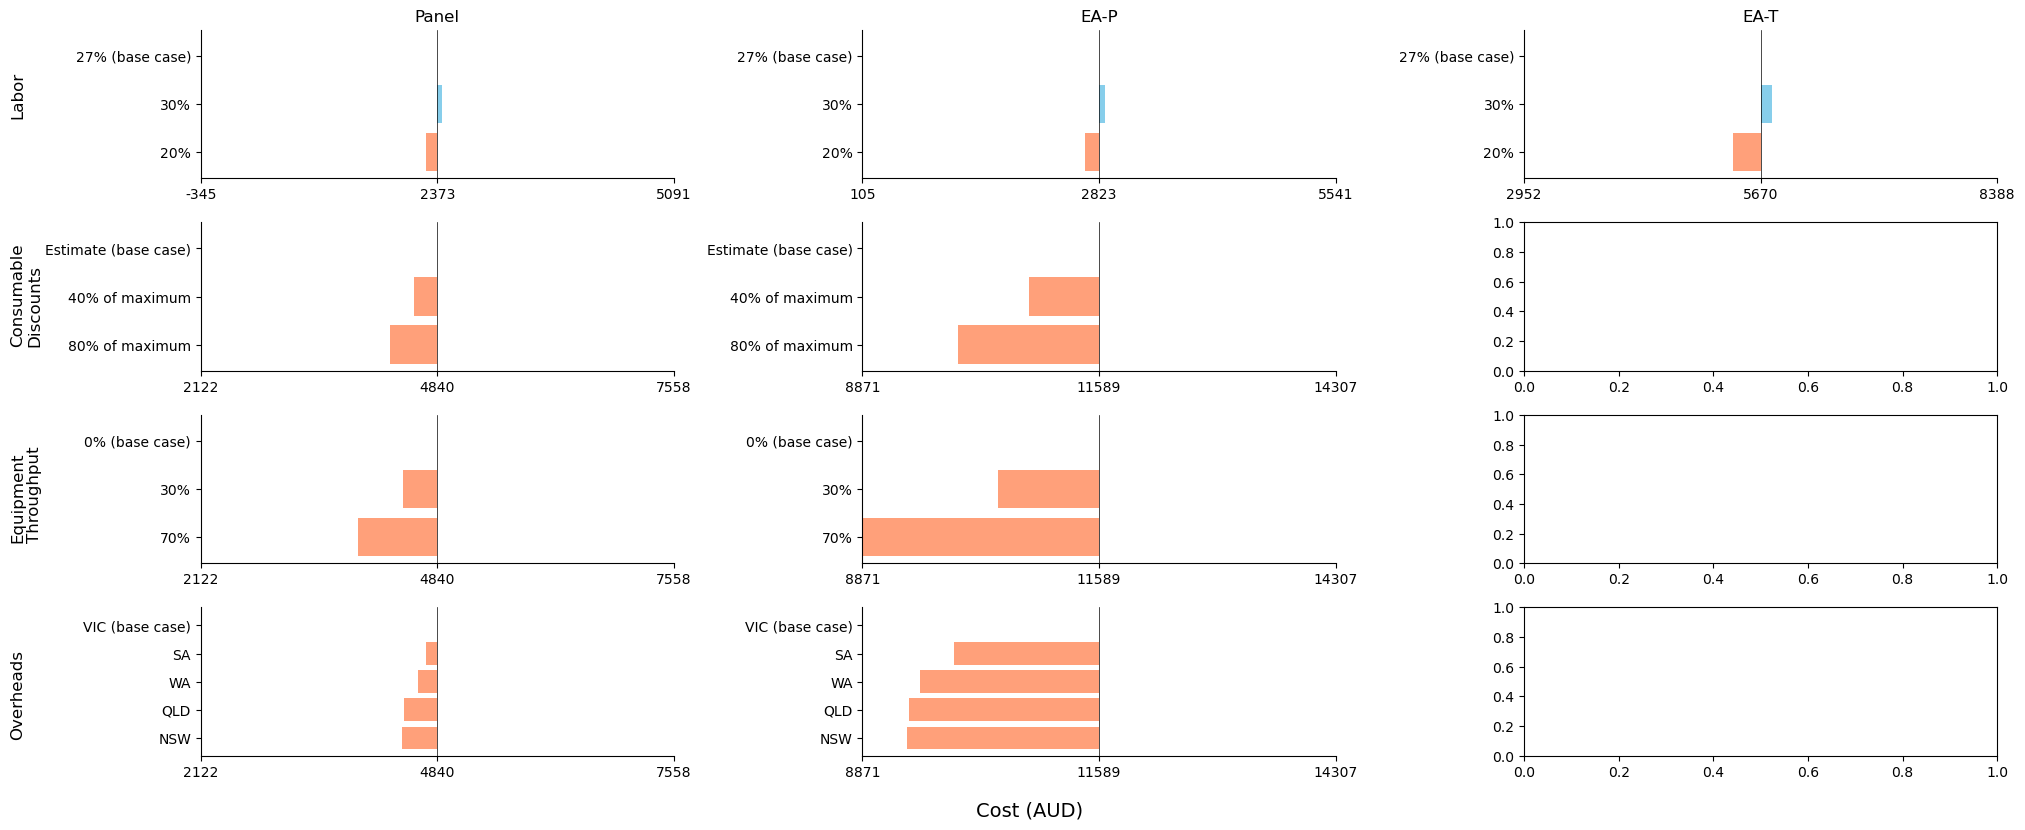

In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Load the data
data = pd.read_csv(
    "/Users/doughnut/Library/CloudStorage/OneDrive-TheUniversityofMelbourne/Phase 1 - Study 1 - Microcosting - Model 1/MicrocostingDSA20230817(Actual).csv",
    usecols=["Test", "Category", "Scenario", "Value"],
)

# Define unique tests and categories for subplots
unique_tests = data["Test"].unique()
unique_categories = data["Category"].unique()

# Define colors for positive and negative differences
positive_color = "#87CEEB"  # Sky blue
negative_color = "#FFA07A"  # Light salmon

# Compute the global maximum absolute difference
global_max_diff = 0
for category in unique_categories:
    for test in unique_tests:
        subset = data[(data["Test"] == test) & (data["Category"] == category)]
        base_case_value = subset[subset["Scenario"].str.contains("base case")][
            "Value"
        ].values[0]
        differences = subset["Value"] - base_case_value
        max_diff = max(abs(differences))
        global_max_diff = max(global_max_diff, max_diff)


# Define a function to plot individual tornado diagrams
def plot_tornado(subset, ax):
    base_case_value = subset[subset["Scenario"].str.contains("base case")][
        "Value"
    ].values[0]
    differences = subset["Value"] - base_case_value
    sorted_indices = np.argsort(np.abs(differences))[::-1]
    sorted_differences = differences.iloc[sorted_indices].values
    sorted_scenarios = subset["Scenario"].iloc[sorted_indices].values
    ax.barh(
        sorted_scenarios,
        sorted_differences,
        color=np.where(sorted_differences >= 0, positive_color, negative_color),
    )
    ax.axvline(x=0, color="black", linewidth=0.5)
    ax.set_xlim(-global_max_diff, global_max_diff)
    ax.set_xticks([-global_max_diff, 0, global_max_diff])
    ax.set_xticklabels(
        [
            int(base_case_value - global_max_diff),
            int(base_case_value),
            int(base_case_value + global_max_diff),
        ]
    )
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["bottom"].set_visible(True)
    ax.spines["left"].set_visible(True)


# Generate the tornado diagrams with further reduced height
fig, axs = plt.subplots(4, 3, figsize=(20, 8), tight_layout=True)

# Adjusted order of tests for the subplot layout
ordered_tests = ["Panel", "EA-P", "EA-T", "WGA-P", "WGA-T"]

for i, category in enumerate(unique_categories):
    if i == 0:
        current_tests = ordered_tests[:3]
    else:
        current_tests = ordered_tests[3:]
    for j, test in enumerate(current_tests):
        subset = data[(data["Test"] == test) & (data["Category"] == category)]
        plot_tornado(subset, axs[i, j])
        if i == 0:
            axs[i, j].set_title(f"{test}")
        if j != 0:
            axs[i, j].set_ylabel("")


# Adjusting the position of the vertical "Category" labels with modified categories
modified_categories = [
    "Overheads",
    "Equipment\nThroughput",
    "Consumable\nDiscounts",
    "Labor",
]

for i, category in enumerate(modified_categories):
    fig.text(
        -0.01,
        (i + 0.5) / 4,
        category,
        fontsize=12,
        rotation=90,
        verticalalignment="center",
    )

# Positioning x-axis label
fig.text(0.5, -0.02, "Cost (AUD)", ha="center", va="center", fontsize=14)

plt.show()

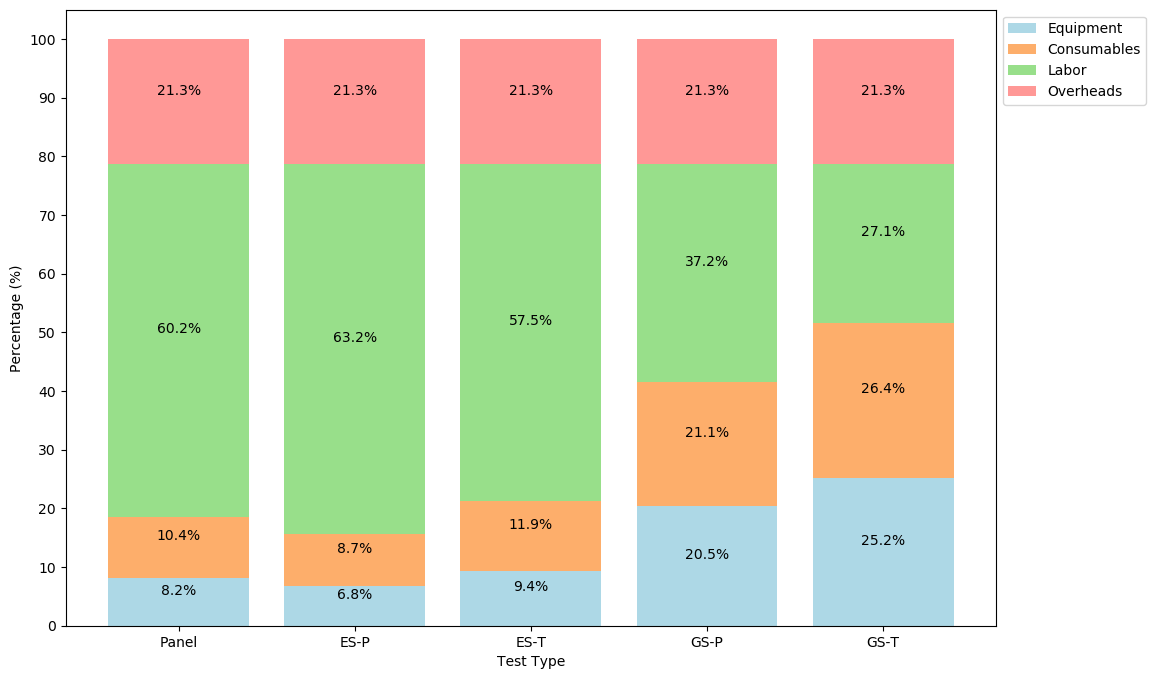

In [3]:
import matplotlib.pyplot as plt
import numpy as np

# Data from the user
categories = ["Panel", "ES-P", "ES-T", "GS-P", "GS-T"]
equipment = np.array([195, 193, 533, 991, 2925])
consumables = np.array([246, 246, 674, 1019, 3058])
labor = np.array([1428, 1784, 3258, 1800, 3143])
overheads = np.array([505, 600, 1205, 1029, 2464])

# Total width for all bars at one x
total_width = 0.8

# Calculating the width for each bar
widest_ind_width = total_width  # Maximum width for the bars

# The x locations for the groups
ind = np.arange(len(categories))

# Lighter colors for the bars
lighter_colors = ["#add8e6", "#fdae6b", "#98df8a", "#ff9896"]

# Calculating percentages
total_values = equipment + consumables + labor + overheads
equipment_percentage = (equipment / total_values) * 100
consumables_percentage = (consumables / total_values) * 100
labor_percentage = (labor / total_values) * 100
overheads_percentage = (overheads / total_values) * 100

# Plotting with widest bars and percentages
plt.figure(figsize=(12, 8))
p1 = plt.bar(
    ind,
    equipment_percentage,
    widest_ind_width,
    color=lighter_colors[0],
    label="Equipment",
)
p2 = plt.bar(
    ind,
    consumables_percentage,
    widest_ind_width,
    bottom=equipment_percentage,
    color=lighter_colors[1],
    label="Consumables",
)
p3 = plt.bar(
    ind,
    labor_percentage,
    widest_ind_width,
    bottom=equipment_percentage + consumables_percentage,
    color=lighter_colors[2],
    label="Labor",
)
p4 = plt.bar(
    ind,
    overheads_percentage,
    widest_ind_width,
    bottom=equipment_percentage + consumables_percentage + labor_percentage,
    color=lighter_colors[3],
    label="Overheads",
)

plt.ylabel("Percentage (%)")
plt.xlabel("Test Type")
plt.xticks(ind, categories)
plt.yticks(np.arange(0, 101, 10))
# Moving the legend to the right of the plot
plt.legend(loc="upper left", bbox_to_anchor=(1, 1))


# Adding labels for percentages
def add_percentage_labels(bars, data):
    for bar, percentage in zip(bars, data):
        height = bar.get_height()
        plt.annotate(
            "{:.1f}%".format(percentage),
            xy=(bar.get_x() + bar.get_width() / 2, bar.get_y() + height / 2),
            xytext=(0, 3),  # 3 points vertical offset
            textcoords="offset points",
            ha="center",
            va="bottom",
        )


add_percentage_labels(p1, equipment_percentage)
add_percentage_labels(p2, consumables_percentage)
add_percentage_labels(p3, labor_percentage)
add_percentage_labels(p4, overheads_percentage)

plt.show()

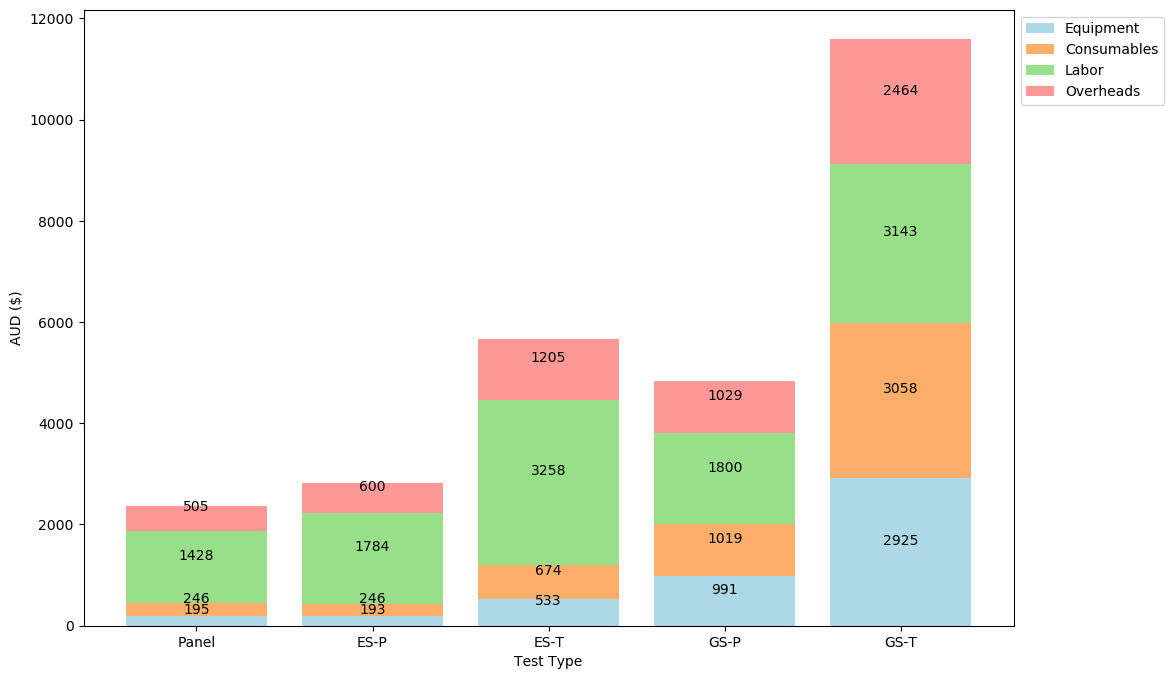

In [4]:
import matplotlib.pyplot as plt
import numpy as np

# Data from the user
categories = ["Panel", "ES-P", "ES-T", "GS-P", "GS-T"]
equipment = np.array([195, 193, 533, 991, 2925])
consumables = np.array([246, 246, 674, 1019, 3058])
labor = np.array([1428, 1784, 3258, 1800, 3143])
overheads = np.array([505, 600, 1205, 1029, 2464])

# Total width for all bars at one x
total_width = 0.8

# The x locations for the groups
ind = np.arange(len(categories))

# Lighter colors for the bars
lighter_colors = ["#add8e6", "#fdae6b", "#98df8a", "#ff9896"]


# Function to add labels to the bars
def add_labels(bars):
    for bar in bars:
        height = bar.get_height()
        plt.annotate(
            "{}".format(height),
            xy=(bar.get_x() + bar.get_width() / 2, bar.get_y() + height / 2),
            xytext=(0, 3),  # 3 points vertical offset
            textcoords="offset points",
            ha="center",
            va="bottom",
        )


# Creating the stacked bar graph
plt.figure(figsize=(12, 8))
p1 = plt.bar(ind, equipment, total_width, color=lighter_colors[0], label="Equipment")
p2 = plt.bar(
    ind,
    consumables,
    total_width,
    bottom=equipment,
    color=lighter_colors[1],
    label="Consumables",
)
p3 = plt.bar(
    ind,
    labor,
    total_width,
    bottom=equipment + consumables,
    color=lighter_colors[2],
    label="Labor",
)
p4 = plt.bar(
    ind,
    overheads,
    total_width,
    bottom=equipment + consumables + labor,
    color=lighter_colors[3],
    label="Overheads",
)

plt.ylabel("AUD ($)")
plt.xlabel("Test Type")
plt.xticks(ind, categories)
plt.yticks(np.arange(0, 12100, 2000))
# Moving the legend to the right of the plot
plt.legend(loc="upper left", bbox_to_anchor=(1, 1))

add_labels(p1)
add_labels(p2)
add_labels(p3)
add_labels(p4)

plt.show()